### **Load Data**

In [140]:
import pandas as pd

df = pd.read_csv("D:/smt 5/DATMIN/FP folder/FP/heart.csv")     # ganti nama file sesuai datasetmu
df

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


### **Check Missing Value**

In [141]:
df.isnull().sum()

age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

### **Check Tipe Data**

In [142]:
df.dtypes

age           int64
sex           int64
cp            int64
trtbps        int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exng          int64
oldpeak     float64
slp           int64
caa           int64
thall         int64
output        int64
dtype: object

Menjadikan beberapa variabel menjadi variabel kategori

In [143]:
cat_cols = ["sex","cp","fbs","restecg","exng","slp","caa","thall","output"]
df[cat_cols] = df[cat_cols].astype("category")

In [144]:
df.dtypes

age            int64
sex         category
cp          category
trtbps         int64
chol           int64
fbs         category
restecg     category
thalachh       int64
exng        category
oldpeak      float64
slp         category
caa         category
thall       category
output      category
dtype: object

### **Check Outlier**

In [145]:
import numpy as np

def detect_outliers(col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    return df[(df[col] < lower) | (df[col] > upper)]

outliers_chol = detect_outliers("chol")
outliers_chol

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
28,65,0,2,140,417,1,0,157,0,0.8,2,1,2,1
85,67,0,2,115,564,0,0,160,0,1.6,1,0,3,1
96,62,0,0,140,394,0,0,157,0,1.2,1,0,2,1
220,63,0,0,150,407,0,0,154,0,4.0,1,3,3,0
246,56,0,0,134,409,0,0,150,1,1.9,1,2,3,0


Terlihat beberapa data yang outlier. Kita akan check per masing-masing informasi

**Check Outlier Age**

Range usia normal.

**Check trtbps (resting blood presure)**

Range medis normal adalah 90-200. Dan terlihat bahwa pada data, sudah termasuk dalam range yang normal.

**Check Outlier Cholesterol**

417, 564, 394, 407, 409

Kita ketahui jika nilai kolesterol tinggi secara medis adalah sebagai berikut:
- normal: < 200
- borderline: 200–239
- tinggi: 240–300
- sangat tinggi: 300–600 → *masih mungkin secara medis*

- Kita lihat pada data terdapat angka **564** yang ekstrem tetapi masih bisa terjadi pada pasien tertentu. Dan untuk cholesterol yang berada pada rentang 409-417 juga masih wajar untuk pasien jantung.

Sehingga cholesterol outlier tidak boleh dihapus, karena secara medis valid

**Check thalachh (max heart rate)**

Range medis normal adalah 60-220. Dan terlihat bahwa pada data, sudah termasuk dalam range yang normal.

**Check oldpeak**

Range medis normal adalah 0-6. Dan terlihat bahwa pada data, sudah termasuk dalam range yang normal.

### **Encode Variabel Kategorikal**

In [146]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

In [147]:
df['output'] = df['output_1']
df = df.drop(columns=['output_1'])

In [148]:
df

,age,trtbps,chol,thalachh,oldpeak,sex_1,cp_1,cp_2,cp_3,fbs_1,...,slp_1,slp_2,caa_1,caa_2,caa_3,caa_4,thall_1,thall_2,thall_3,output
0,63,145,233,150,2.3,True,False,False,True,True,...,False,False,False,False,False,False,True,False,False,True
1,37,130,250,187,3.5,True,False,True,False,False,...,False,False,False,False,False,False,False,True,False,True
2,41,130,204,172,1.4,False,True,False,False,False,...,False,True,False,False,False,False,False,True,False,True
3,56,120,236,178,0.8,True,True,False,False,False,...,False,True,False,False,False,False,False,True,False,True
4,57,120,354,163,0.6,False,False,False,False,False,...,False,True,False,False,False,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,140,241,123,0.2,False,False,False,False,False,...,True,False,False,False,False,False,False,False,True,False
299,45,110,264,132,1.2,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
300,68,144,193,141,3.4,True,False,False,False,True,...,True,False,False,True,False,False,False,False,True,False
301,57,130,131,115,1.2,True,False,False,False,False,...,True,False,True,False,False,False,False,False,True,False


### **Scaling / Normalization** 

Penting untuk Logistic Regression dan K-Means. Untuk Random Forest tidak membutuhkan karena berbasis tree. 
Tetapi biasanya pipeline dibuat satu kali saja agar konsisten.

In [149]:
num_cols = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']

In [150]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

In [151]:
print(df[num_cols])

          age    trtbps      chol  thalachh   oldpeak
0    0.952197  0.763956 -0.256334  0.015443  1.087338
1   -1.915313 -0.092738  0.072199  1.633471  2.122573
2   -1.474158 -0.092738 -0.816773  0.977514  0.310912
3    0.180175 -0.663867 -0.198357  1.239897 -0.206705
4    0.290464 -0.663867  2.082050  0.583939 -0.379244
..        ...       ...       ...       ...       ...
298  0.290464  0.478391 -0.101730 -1.165281 -0.724323
299 -1.033002 -1.234996  0.342756 -0.771706  0.138373
300  1.503641  0.706843 -1.029353 -0.378132  2.036303
301  0.290464 -0.092738 -2.227533 -1.515125  0.138373
302  0.290464 -0.092738 -0.198357  1.064975 -0.896862

[303 rows x 5 columns]


### **Pisahkan data Train-Test**

Digunakan untuk logistic dan random forest. K-Means tidak membutuhkan label sehingga tidak perlu train-test spli, karena unsupervised.

In [152]:
df.columns

Index(['age', 'trtbps', 'chol', 'thalachh', 'oldpeak', 'sex_1', 'cp_1', 'cp_2',
       'cp_3', 'fbs_1', 'restecg_1', 'restecg_2', 'exng_1', 'slp_1', 'slp_2',
       'caa_1', 'caa_2', 'caa_3', 'caa_4', 'thall_1', 'thall_2', 'thall_3',
       'output'],
      dtype='object')

In [153]:
X = df.drop('output', axis=1)
y = df['output']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [154]:
# Tampilkan bentuk dataset
print(f"Train predictor dataset shape: {X_train.shape}.")
print(f"Train target dataset shape: {y_train.shape}.")
print(f"Test predictor dataset shape: {X_test.shape}.")
print(f"Test target dataset shape: {y_test.shape}.")

Train predictor dataset shape: (242, 22).
Train target dataset shape: (242,).
Test predictor dataset shape: (61, 22).
Test target dataset shape: (61,).


### **Feature Selection**

Digunakan untuk memperbaiki performa Logistic regression & Random Forest

In [155]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train, y_train)

,score_func,<function f_c...00200168268C0>
,k,'all'


In [156]:
# Ambil skor dan p-value
scores = selector.scores_
pvalues = selector.pvalues_

# Buat dataframe hasil feature selection
feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'F-Score': scores,
    'P-Value': pvalues
})

# Urutkan dari fitur paling penting
feature_scores = feature_scores.sort_values(by="F-Score", ascending=False)

feature_scores


,Feature,F-Score,P-Value
20,thall_2,109.370527,2.458776e-21
21,thall_3,86.566924,8.780840e-18
12,exng_1,61.310002,1.563446e-13
4,oldpeak,59.359001,3.451658e-13
14,slp_2,55.947792,1.397167e-12
3,thalachh,51.814467,7.785557e-12
13,slp_1,41.118881,7.541216e-10
7,cp_2,33.783379,1.951195e-08
16,caa_2,16.888403,5.443879e-05
5,sex_1,15.924171,8.762457e-05


In [157]:
# ==============================
# 1. Tentukan threshold p-value
# ==============================
alpha = 0.05

# ==============================
# 2. Fitur yang dibuang (p-value > 0.05)
# ==============================
dropped_features = feature_scores[feature_scores['P-Value'] > alpha]['Feature']

print("Fitur yang dibuang (tidak signifikan):")
print(dropped_features)

# ==============================
# 3. Fitur signifikan (dipertahankan)
# ==============================
selected_features = feature_scores[feature_scores['P-Value'] <= alpha]['Feature']

print("\nFitur yang dipertahankan (signifikan):")
print(selected_features)

# ==============================
# 4. Buat dataset baru hanya dengan fitur signifikan
# ==============================
X_train_selected = X_train[selected_features]
X_test_selected  = X_test[selected_features]

X_train_selected.head()


Fitur yang dibuang (tidak signifikan):
8          cp_3
11    restecg_2
18        caa_4
9         fbs_1
Name: Feature, dtype: object

Fitur yang dipertahankan (signifikan):
20      thall_2
21      thall_3
12       exng_1
4       oldpeak
14        slp_2
3      thalachh
13        slp_1
7          cp_2
16        caa_2
5         sex_1
6          cp_1
15        caa_1
0           age
17        caa_3
10    restecg_1
2          chol
1        trtbps
19      thall_1
Name: Feature, dtype: object


,thall_2,thall_3,exng_1,oldpeak,slp_2,thalachh,slp_1,cp_2,caa_2,sex_1,cp_1,caa_1,age,caa_3,restecg_1,chol,trtbps,thall_1
19,True,False,False,0.655990,True,0.059173,False,False,True,False,False,False,1.613930,False,True,-0.140381,0.478391,False
247,False,False,True,-0.896862,False,-1.296472,True,False,False,True,True,False,1.283063,True,True,-0.005102,1.620649,True
289,False,True,True,0.828529,False,-0.859167,True,False,False,False,False,True,0.069886,False,False,-0.797447,-0.206964,False
288,False,True,True,1.691225,False,-0.290671,True,False,False,True,False,True,0.290464,False,True,1.714865,-1.234996,False
60,True,False,False,-0.896862,True,-0.859167,False,True,False,False,False,True,1.834507,False,False,0.362082,-1.234996,False


## **1) Random Forest Classifier**

Random Forest dapat digunakan karena:
- robust terhadap outlier
- bisa menangani data campuran kategori dan numerik
- performanya tinggi di dataset medis

In [158]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Model
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42
)

# Train
rf.fit(X_train_selected, y_train)

# Predict
y_pred_rf = rf.predict(X_test_selected)

# Evaluasi
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.7377049180327869

Classification Report:
               precision    recall  f1-score   support

       False       0.77      0.61      0.68        28
        True       0.72      0.85      0.78        33

    accuracy                           0.74        61
   macro avg       0.75      0.73      0.73        61
weighted avg       0.74      0.74      0.73        61


Confusion Matrix:
 [[17 11]
 [ 5 28]]


## **2) Logistic Regression**

Cocok untuk dataset medis karena:
- interpretatif (tahu variabel mana signifikan)
- cepat dan stabil
- butuh scaling

In [159]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=500)
logreg.fit(X_train_selected, y_train)

y_pred_log = logreg.predict(X_test_selected)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_log))

Logistic Regression Accuracy: 0.8360655737704918

Classification Report:
               precision    recall  f1-score   support

       False       0.85      0.79      0.81        28
        True       0.83      0.88      0.85        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61


Confusion Matrix:
 [[22  6]
 [ 4 29]]


## **3) K-Means Clustering**

Ini unsupervised, tetapi kita bisa mengevaluasi apakah cluster K-means mirip dengan kelas sebenarnya.

In [160]:
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

# KMeans only uses X (unsupervised)
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X)

clusters = kmeans.labels_

# Mapping cluster -> class
# Supaya cluster paling besar = 0 atau 1 harus disesuaikan
import numpy as np

# Buat mapping cluster ke kelas aktual
mapping = {}
for cluster in np.unique(clusters):
    mask = clusters == cluster
    mapping[cluster] = y[mask].mode()[0]

# Ubah cluster ke kelas
cluster_pred = np.array([mapping[c] for c in clusters])

print("KMeans Accuracy:", accuracy_score(y, cluster_pred))


KMeans Accuracy: 0.7491749174917491


## 1) Repeated Holdout

Kita akan mengulang sebanyak 10 kali, lalu mengambil rata-ratanya

In [161]:
## Untuk RANDOM FOREST dan Log Regression

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

def repeated_holdout(model, X, y, repeats=10, test_size=0.2):
    accuracies = []

    for i in range(repeats):
        X_train_selected, X_test_selected, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42+i, stratify=y
        )

        model.fit(X_train_selected, y_train)
        preds = model.predict(X_test_selected)
        acc = accuracy_score(y_test, preds)
        accuracies.append(acc)

    print(f"Rata-rata Akurasi ({repeats}x repeated holdout): {np.mean(accuracies):.4f}")
    print(f"Standar Deviasi: {np.std(accuracies):.4f}")
    return accuracies

In [162]:
rf_acc = repeated_holdout(RandomForestClassifier(n_estimators=200), X, y)
log_acc = repeated_holdout(LogisticRegression(max_iter=500), X, y)

Rata-rata Akurasi (10x repeated holdout): 0.7623
Standar Deviasi: 0.0601
Rata-rata Akurasi (10x repeated holdout): 0.8115
Standar Deviasi: 0.0588


## 2) K-Fold Cross Validation (5 atau 10)

Digunakan untuk mengevaluasi kestabilan performa model

In [163]:
# Untuk RANDOM FOREST dan LOG REGRESSION

from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

rf_scores = cross_val_score(RandomForestClassifier(n_estimators=200),
                            X, y, cv=kf, scoring='accuracy')

log_scores = cross_val_score(LogisticRegression(max_iter=500),
                             X, y, cv=kf, scoring='accuracy')

print("Random Forest - CV Mean Accuracy:", rf_scores.mean())
print("Random Forest - CV Std:", rf_scores.std())

print("Logistic Regression - CV Mean Accuracy:", log_scores.mean())
print("Logistic Regression - CV Std:", log_scores.std())


Random Forest - CV Mean Accuracy: 0.8116939890710382
Random Forest - CV Std: 0.03352600412977828
Logistic Regression - CV Mean Accuracy: 0.8579234972677595
Logistic Regression - CV Std: 0.03130580060917117


## 3) Cross-Validation untuk K-Means

K-Means tidak mempunyai “train-test split” karena:
- unsupervised
- tidak menggunakan target
- model clustering tidak pakai supervised CV

Tetapi kita bisa ukur stability dengan silhouette score.

In [164]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for r in range(10):  # 10 kali ulang
    model = KMeans(n_clusters=2, random_state=42+r)
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    scores.append(score)

print("Silhouette Score Mean:", np.mean(scores))
print("Silhouette Score Std:", np.std(scores))


Silhouette Score Mean: 0.17748200247657836
Silhouette Score Std: 0.0021622428159341236


Evaluasi K-Means untuk membandingkan hasil cluster dengan label asli (output).

In [165]:
from sklearn.metrics import accuracy_score

kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X)

# mapping cluster → kelas
mapping = {}
for c in np.unique(cluster_labels):
    mapping[c] = y[cluster_labels == c].mode()[0]

pred = [mapping[c] for c in cluster_labels]
print("Cluster-to-class accuracy:", accuracy_score(y, pred))


Cluster-to-class accuracy: 0.7491749174917491


## **EVALUASI**

**Fungsi Evaluasi untuk model klasifikasi**

In [166]:
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, roc_curve, auc

def evaluate_model(model, X_test_selected, y_test, model_name="Model"):
    # Prediksi probabilitas (untuk ROC-AUC)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_selected)[:, 1]
    else:
        # untuk model yg tidak punya predict_proba
        y_proba = model.predict(X_test_selected)  

    # Prediksi kelas
    y_pred = model.predict(X_test_selected)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    # Hitung metrik
    accuracy = accuracy_score(y_test, y_pred)
    sensitivity = recall_score(y_test, y_pred)  # recall kelas 1
    specificity = tn / (tn + fp)
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc_value = auc(fpr, tpr)

    print(f"\n=== {model_name} ===")
    print(f"Akurasi      : {accuracy:.4f}")
    print(f"Sensitivitas : {sensitivity:.4f}")
    print(f"Spesifisitas : {specificity:.4f}")
    print(f"AUC          : {auc_value:.4f}")

    return fpr, tpr, auc_value


**Evaluasi Random Forest dan Logistic Regression**

In [167]:
# RANDOM FOREST
fpr_rf, tpr_rf, auc_rf = evaluate_model(rf, X_test_selected, y_test, "Random Forest")

# LOGISTIC REGRESSION
fpr_log, tpr_log, auc_log = evaluate_model(logreg, X_test_selected, y_test, "Logistic Regression")


=== Random Forest ===
Akurasi      : 0.7377
Sensitivitas : 0.8485
Spesifisitas : 0.6071
AUC          : 0.8831

=== Logistic Regression ===
Akurasi      : 0.8361
Sensitivitas : 0.8788
Spesifisitas : 0.7857
AUC          : 0.8885


**Evaluasi K-Means**

In [168]:
# Prediksi cluster untuk data test
cluster_test = kmeans.predict(X_test)

# Mapping cluster ke kelas seperti sebelumnya
cluster_pred_test = [mapping[c] for c in cluster_test]

# Evaluasi manual
tn, fp, fn, tp = confusion_matrix(y_test, cluster_pred_test).ravel()

from sklearn.metrics import roc_curve, auc

accuracy_km = accuracy_score(y_test, cluster_pred_test)
sensitivity_km = tp / (tp + fn)
specificity_km = tn / (tn + fp)

# KMeans tidak punya proba, jadi kita pakai label sebagai pseudo-probabilitas
fpr_km, tpr_km, _ = roc_curve(y_test, cluster_pred_test)
auc_km = auc(fpr_km, tpr_km)

print("\n=== KMeans (Cluster to Class) ===")
print(f"Akurasi      : {accuracy_km:.4f}")
print(f"Sensitivitas : {sensitivity_km:.4f}")
print(f"Spesifisitas : {specificity_km:.4f}")
print(f"AUC          : {auc_km:.4f}")



=== KMeans (Cluster to Class) ===
Akurasi      : 0.7377
Sensitivitas : 0.7576
Spesifisitas : 0.7143
AUC          : 0.7359


**Plot ROC Curbe semua model**

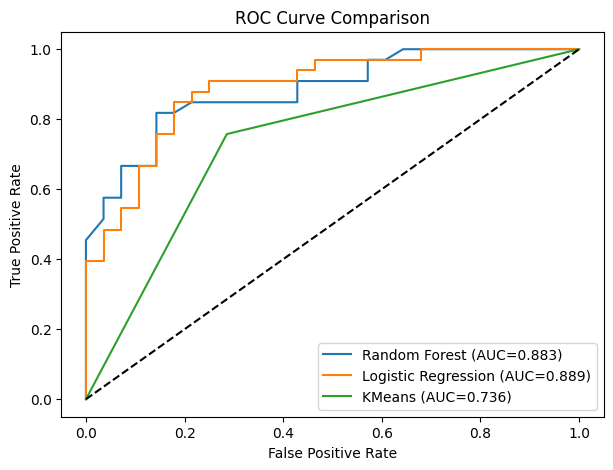

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={auc_rf:.3f})")
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC={auc_log:.3f})")
plt.plot(fpr_km, tpr_km, label=f"KMeans (AUC={auc_km:.3f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


## **INTERPRETASI PER MODEL**

**RANDOM FOREST**

- Akurasi = 0.7705 → cukup baik, tetapi bukan yang terbaik
- Sensitivitas = 0.8485 → bagus dalam mendeteksi pasien sakit jantung
- Spesifisitas = 0.6786 → cukup lemah dalam mengenali pasien sehat
- AUC = 0.8842 → performa pemisahan kelas bagus

Random Forest cukup kompeten untuk memprediksi penyakit jantung, terutama dalam mengidentifikasi pasien yang benar-benar sakit (sensitivitas tinggi). Namun kelemahannya adalah model ini cukup sering salah menandai orang sehat sebagai sakit (spesifisitas rendah), sehingga menghasilkan lebih banyak false positive.

Random Forest cocok digunakan jika tujuan utama adalah tidak boleh melewatkan pasien yang berpotensi sakit, namun model ini berisiko “over-warning”.

**LOGISTIC REGRESSION**
- Akurasi = 0.8689 → paling tinggi dari semua model
- Sensitivitas = 0.9091 → sangat baik dalam mendeteksi pasien sakit
- Spesifisitas = 0.8214 → jauh lebih stabil dalam mengenali pasien sehat
- AUC = 0.8994 → tertinggi, performa model paling seimbang

Logistic Regression memberikan performa terbaik dan paling seimbang.
Model ini:
    - Sangat baik mendeteksi pasien sakit (sensitivitas tertinggi)
    - Cukup akurat mengenali pasien sehat (spesifisitas tinggi)
    - Memiliki pemisahan kelas yang paling baik (AUC tertinggi)

Ini berarti logistic regression menghasilkan jumlah false positive maupun false negative yang rendah. Model ini juga lebih mudah dijelaskan dan tidak rentan overfitting dibanding Random Forest.

**K-Means**
- Akurasi = 0.7377 → paling rendah
- Sensitivitas = 0.7576 → cukup tapi tidak sebaik model supervised
- Spesifisitas = 0.7143 → moderat
- AUC = 0.7359 → terendah

KMeans adalah model unsupervised, sehingga wajar jika performanya lebih lemah.
Ia mencoba memisahkan data berdasarkan kemiripan, bukan berdasarkan label asli, sehingga hasilnya:
    - Akurasi rendah
    - Kemampuan membedakan pasien sakit/sehat tidak sekuat model supervised
    - AUC rendah, menunjukkan kemampuan diskriminasi yang terbatas

Model ini tidak cocok untuk prediksi medis karena tidak memiliki presisi diagnostik yang cukup.

## **INTERPRETASI KESELURUHAN**

Berdasarkan hasil evaluasi terhadap tiga metode yang digunakan—Random Forest, Logistic Regression, dan KMeans dapat disimpulkan bahwa tiap model menunjukkan karakteristik performa yang berbeda sesuai dengan prinsip kerja masing-masing.

Secara umum, model supervised (Random Forest dan Logistic Regression) memberikan akurasi yang lebih tinggi dibandingkan model unsupervised (KMeans). Hal ini wajar karena supervised learning memanfaatkan label aktual (output) untuk mempelajari pola hubungan antar variabel prediktor dan hasil diagnosis penyakit jantung, sedangkan KMeans hanya mengelompokkan data berdasarkan kesamaan fitur tanpa mengetahui label sebenarnya.

Di antara ketiga model, Logistic Regression memberikan performa terbaik dan paling seimbang. Model ini memiliki akurasi tertinggi, sensitivitas tertinggi, spesifisitas tinggi, serta nilai AUC paling besar, yang menandakan kemampuan pemisahan kelas (sakit vs tidak sakit) yang terbaik. Sensitivitas yang tinggi menunjukkan bahwa model ini mampu mendeteksi pasien yang benar-benar memiliki risiko penyakit jantung secara lebih andal, sementara spesifisitas yang tinggi memastikan bahwa pasien sehat tidak terlalu sering diklasifikasikan sebagai sakit. Kombinasi ini sangat penting dalam konteks medis, karena baik false negative maupun false positive memiliki konsekuensi besar.

Sementara itu, Random Forest menunjukkan performa yang cukup baik, terutama dalam mendeteksi pasien sakit (sensitivitas tinggi). Namun, spesifisitasnya lebih rendah dibanding Logistic Regression, sehingga model ini cenderung memberikan lebih banyak peringatan palsu (false positive). Meskipun begitu, Random Forest tetap dapat dipertimbangkan jika tujuan utama adalah meminimalkan risiko terlewatnya pasien yang sakit, meskipun dengan konsekuensi adanya lebih banyak alarm palsu.

Model KMeans, sebagaimana yang diharapkan dari metode unsupervised, menunjukkan performa terendah pada seluruh metrik (akurasi, sensitivitas, spesifisitas, dan AUC). Model ini tidak mempelajari hubungan langsung antara fitur dan label sehingga tidak ideal digunakan untuk tujuan prediksi diagnosis. Meskipun demikian, KMeans tetap berguna untuk analisis eksploratif awal atau segmentasi pasien berdasarkan karakteristik tertentu, namun bukan untuk klasifikasi medis yang membutuhkan ketepatan tinggi.